# 01. Importing Libraries

In [2]:
import os
import math
import random
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import scipy
import numpy as np
import pandas as pd

# 02. Importing Data

In [3]:
amazon = pd.read_csv('../../../IronHack/Unit 5 - EDA and Inferential Stats/amz_uk_price_prediction_dataset.csv')

In [4]:
amazon.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
amazon.shape

(2443651, 9)

# 03. Lab EDA Univariate

## Part 1: Understanding Product Categories

In [6]:
# Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?
# Generate a frequency table for the product category.
# Which are the top 5 most listed product categories?
frequency_table = amazon['category'].value_counts()

In [7]:
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

Top 5 products: sports&outdoors, beauty, handmande clothing, shoes & accessories, bath&body, birthday gifts

C:\Users\gabri\AppData\Local\Temp\ipykernel_46392\2457896883.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=amazon, x='category', palette="Set3");


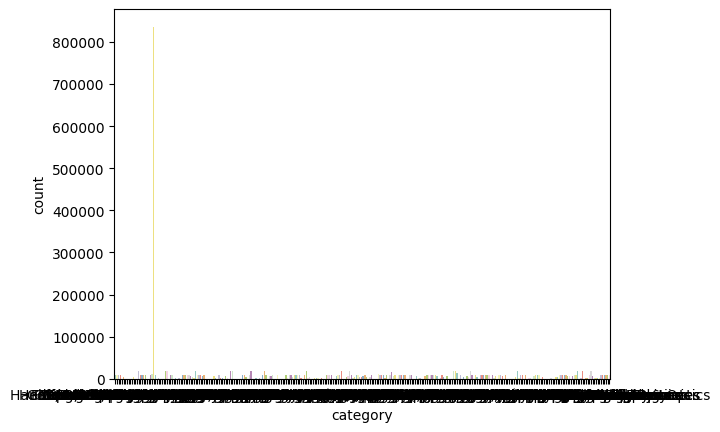

In [12]:
# Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
sns.countplot(data=amazon, x='category', palette="Set3");

C:\Users\gabri\AppData\Local\Temp\ipykernel_46392\3511691366.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=amazon_top5, x='category', palette="Set3");


([0, 1, 2, 3, 4],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Birthday Gifts'),
  Text(2, 0, 'Bath & Body'),
  Text(3, 0, 'Beauty'),
  Text(4, 0, 'Handmade Clothing, Shoes & Accessories')])

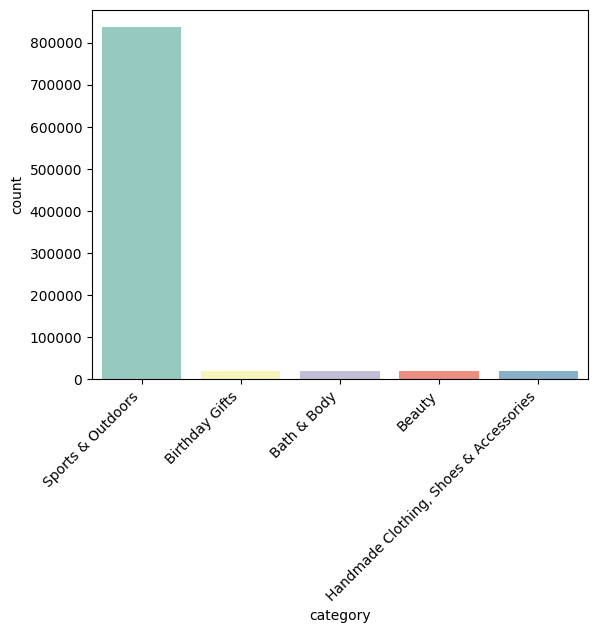

In [14]:
sns.countplot(data=amazon_top5, x='category', palette="Set3");
plt.xticks(rotation=45, horizontalalignment='right')

In [8]:
top5 = amazon['category'].value_counts().head(5).index

In [9]:
amazon_top5 = amazon[amazon['category'].isin(top5)]   

<Axes: >

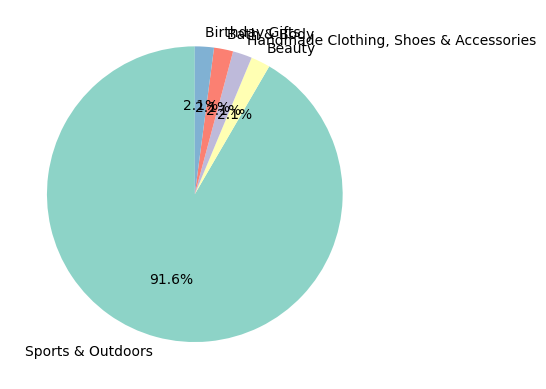

In [11]:
# For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?
amazon_top5['category'].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))

## Part 2: Delving into Product Pricing

In [18]:
# Calculate the mean, median, and mode for the price of products.
# What's the average price point of products listed? How does this compare with the most common price point (mode)?

print('Average price:', amazon['price'].mean())
print('Median price:', amazon['price'].median())
print('Mode price:', amazon['price'].mode())
print('Price range:', amazon['price'].min(), '-', amazon['price'].max())

Average price: 89.24380943923661
Median price: 19.09
Mode price: 0    9.99
Name: price, dtype: float64
Price range: 0.0 - 100000.0


The average is much higher than the median and the mode - the mode being 0 and 9.99 

This means that there are products that do have much higher prices and are puling the average up

In [20]:
# Determine the variance, standard deviation, range, and interquartile range for product price.
# How varied are the product prices? Are there any indicators of a significant spread in prices?
print('Price variance:', amazon['price'].var())
print('Price standard deviation:', amazon['price'].std())
print('Price range:', amazon['price'].min(), '-', amazon['price'].max())
print('Q1 (25th percentile):', amazon['price'].quantile(0.25))
print('Q3 (75th percentile):', amazon['price'].quantile(0.75))
print('Price interquartile range:', amazon['price'].quantile(0.75) - amazon['price'].quantile(0.25))


Price variance: 119445.48532254901
Price standard deviation: 345.60886175349873
Price range: 0.0 - 100000.0
Q1 (25th percentile): 9.99
Q3 (75th percentile): 45.99
Price interquartile range: 36.0


There is a very big spread on the prices - the highest price seen is 100k (which would indicate a data error)

Also, the high STD indicates a high spread on the prices

The IQRs indicate that most of the prices are within 9.99 and 45.99

<Axes: xlabel='price', ylabel='Count'>

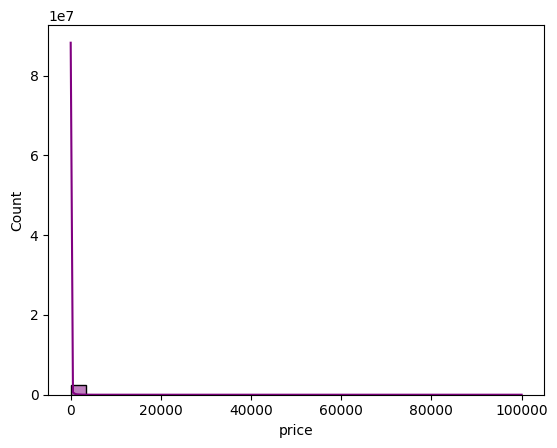

In [30]:
# Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. 
# If its hard to read these diagrams, think why this is, and explain how it could be solved..
sns.histplot(amazon['price'], kde=True, bins=30, color="purple")

In [24]:
# excluding outliers
Q1 = amazon['price'].quantile(0.25)
Q3 = amazon['price'].quantile(0.75)

In [25]:
IQR = Q3 - Q1

In [26]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [27]:
amazon_no_outliers = amazon[(amazon['price'] >= lower_bound) & (amazon['price'] <= upper_bound)]

<Axes: xlabel='price', ylabel='Count'>

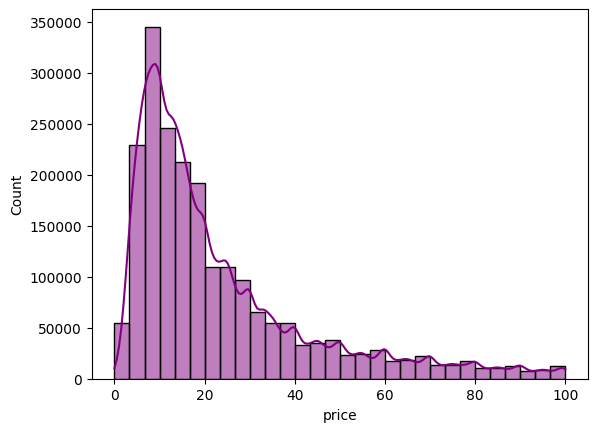

In [29]:
sns.histplot(amazon_no_outliers['price'], kde=True, bins=30, color="purple")

<Axes: ylabel='price'>

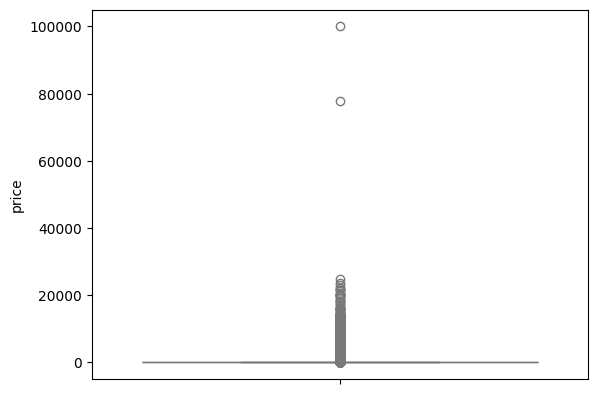

In [31]:
# Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.
sns.boxplot(data = amazon['price'], color="lightblue")

Looks like there are 2 products that are priced way higher than the others (indicating possible data issue)

<Axes: ylabel='price'>

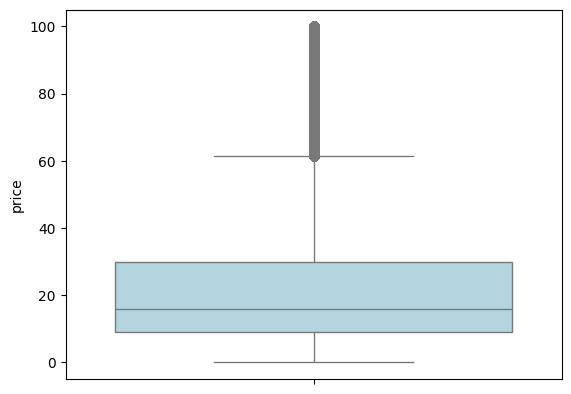

In [ ]:
# same but without outliers
sns.boxplot(data = amazon_no_outliers['price'], color="lightblue")

## Part 3: Unpacking Product Ratings

In [33]:
# Calculate the mean, median, and mode for the rating of products.
# How do customers generally rate products? Is there a common trend?
print('Average rating:', amazon['stars'].mean())
print('Median rating:', amazon['stars'].median())
print('Mode rating:', amazon['stars'].mode())
print('Rating range:', amazon['stars'].min(), '-', amazon['stars'].max())

Average rating: 2.152836472966066
Median rating: 0.0
Mode rating: 0    0.0
Name: stars, dtype: float64
Rating range: 0.0 - 5.0


There are ratings in all 5 possible tiers (stars), but the average is 2.15, which quite surprised me. However, when I see the median and the mode I can see that, most customers do not rate the products

In [34]:
# Determine the variance, standard deviation, and interquartile range for product rating.
# Are the ratings consistent, or is there a wide variation in customer feedback?
print('Rating variance:', amazon['stars'].var())
print('Rating standard deviation:', amazon['stars'].std())
print('Rating range:', amazon['stars'].min(), '-', amazon['stars'].max())
print('Q1 (25th percentile):', amazon['stars'].quantile(0.25))
print('Q3 (75th percentile):', amazon['stars'].quantile(0.75))
print('Rating interquartile range:', amazon['stars'].quantile(0.75) - amazon['stars'].quantile(0.25))

Rating variance: 4.817434029796864
Rating standard deviation: 2.194865378513421
Rating range: 0.0 - 5.0
Q1 (25th percentile): 0.0
Q3 (75th percentile): 4.4
Rating interquartile range: 4.4


Customers rate products in all tiers (stars) possible and availble. Most ratings are in between 0-4.4, which shows that it is a bit more difficult to get 5 star rating

In [37]:
# Calculate the skewness and kurtosis for the rating column.
# Are the ratings normally distributed, or do they lean towards higher or lower values?
print("Skewness:", amazon['stars'].skew())
print("Kurtosis:", amazon['stars'].kurt())

Skewness: 0.08120735761080881
Kurtosis: -1.9260061280432994


Data is almost symmetric (close to 0) - normally distributed, and the line of distribution is flat (as the number is negative)

<Axes: xlabel='stars', ylabel='Count'>

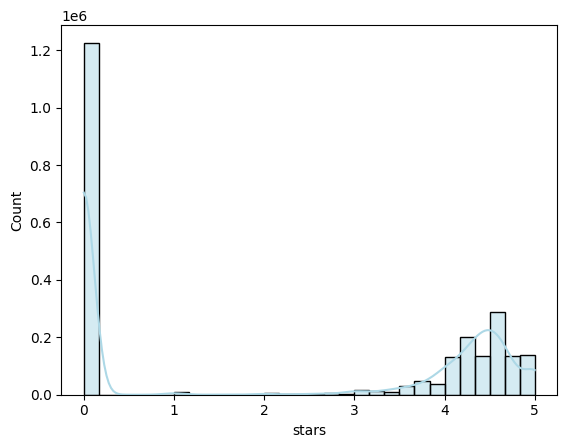

In [36]:
# Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
sns.histplot(amazon['stars'], kde=True, bins=30, color="lightblue")

0 stars is the most commum, but all the non-evaluated products go into. From actual actionable ratings, between 4 and 5 have the most count. It shows that people tend to evaluate if they are happy with the product they purchased